### Credit Card Fraud Detection — Playground S6E11

**Goal:** predict `is_fraud` while minimizing business cost (missed fraud + false-alarm friction).

**Metric:** PR-AUC (honest for imbalance) + recall@fixed-FPR (production) + business cost curve.

In [1]:
# ---- Setup ----
from pathlib import Path
import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score, confusion_matrix,
)
import lightgbm as lgb

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 100)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR     = PROJECT_ROOT / "data"
REPORTS_DIR  = PROJECT_ROOT / "reports" / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

TARGET, ID_COL = "is_fraud", "id"
print("Project root:", PROJECT_ROOT)
print("Data exists :", (DATA_DIR / "train.csv").exists())

Project root: /home/prashant/Projects/fraud-detection-2026
Data exists : True


In [2]:
#LLoad Data
train = pd.read_csv(DATA_DIR / "train.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")
print(f"Train: {train.shape}  Test: {test.shape}")
print(f"Target rate: {train[TARGET].mean()*100:.3f}%")

Train: (699960, 26)  Test: (299984, 25)
Target rate: 1.670%


is_fraud
0.0    688271
1.0     11689

Fraud: 1.670%  → 1 fraud per 58.9 legit
→ 'Predict all 0' accuracy = 98.33%  (accuracy is BANNED)


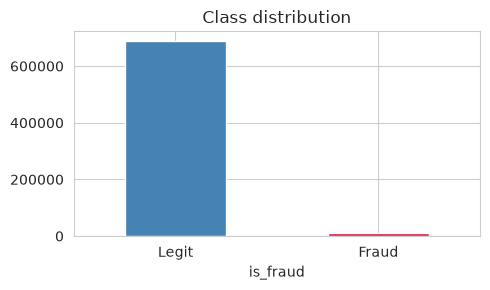

In [4]:
## Data Imbalance 
counts = train[TARGET].value_counts().sort_index()
pct    = train[TARGET].value_counts(normalize=True).sort_index() * 100
print(counts.to_string())
print(f"\nFraud: {pct[1]:.3f}%  → 1 fraud per {counts[0]/counts[1]:.1f} legit")
print(f"→ 'Predict all 0' accuracy = {pct[0]:.2f}%  (accuracy is BANNED)")

fig, ax = plt.subplots(figsize=(5, 3))
counts.plot(kind="bar", ax=ax, color=["steelblue", "crimson"])
ax.set_xticklabels(["Legit", "Fraud"], rotation=0)
ax.set_title("Class distribution")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "imbalance.png", dpi=120); plt.show()

In [5]:
schema = pd.DataFrame({
    "dtype":       train.dtypes,
    "n_missing":   train.isnull().sum(),
    "n_unique":    train.nunique(),
}).sort_values("n_missing", ascending=False)
print(schema.to_string())
print(f"\nTotal missing: {train.isnull().sum().sum():,}")

                                dtype  n_missing  n_unique
id                              int64          0    699960
amount_usd                    float64          0     13387
hours_since_last_txn          float64          0      3633
txn_count_last_24h              int64          0        12
distance_from_home_km         float64          0      4365
card_age_months                 int64          0        49
customer_age                    int64          0        64
account_balance_usd           float64          0     43317
cvv_retry_count                 int64          0         4
velocity_score                float64          0       666
time_of_day_hour                int64          0        24
day_of_week                     int64          0         7
merchant_risk_score           float64          0       950
prior_disputes                  int64          0         5
merchant_category                 str          0        12
card_type                         str          0        

In [6]:
# Feature engineering 
SKEWED = ["amount_usd", "distance_from_home_km", "account_balance_usd"]

def add_features(df):
    df = df.copy()
    cols = set(df.columns)
    for c in SKEWED:
        if c in cols:
            df[f"log_{c}"] = np.log1p(df[c].clip(lower=0))
    if {"velocity_score", "hours_since_last_txn"}.issubset(cols):
        df["velocity_per_hour"] = df["velocity_score"] / (df["hours_since_last_txn"] + 1)
    if {"cvv_retry_count", "prior_disputes"}.issubset(cols):
        df["risk_stack"] = df["cvv_retry_count"] + df["prior_disputes"]
    if {"txn_count_last_24h", "amount_usd"}.issubset(cols):
        df["amount_per_txn_24h"] = df["amount_usd"] / (df["txn_count_last_24h"] + 1)
    return df

train = add_features(train)
test  = add_features(test)

# ---- Split (stratified) ----
X = train.drop(columns=[TARGET, ID_COL])
y = train[TARGET].astype(int)
X_test_final = test.drop(columns=[ID_COL])

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ---- Auto-discover feature types ----
cat_cols = X_tr.select_dtypes(include=["object", "string", "category"]).columns.tolist()
num_cols = [c for c in X_tr.columns if c not in cat_cols]

print(f"Train: {X_tr.shape}  Val: {X_val.shape}  Test: {X_test_final.shape}")
print(f"Fraud in train: {y_tr.mean()*100:.3f}%  in val: {y_val.mean()*100:.3f}%")
print(f"Numeric: {len(num_cols)}  Categorical: {len(cat_cols)}")
print(f"Categorical columns: {cat_cols}")

Train: (559968, 30)  Val: (139992, 30)  Test: (299984, 30)
Fraud in train: 1.670%  in val: 1.670%
Numeric: 25  Categorical: 5
Categorical columns: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


In [7]:
# Preprocessing pipeline 
def build_preprocessor():
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale",  StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ])

In [8]:
# Evaluation function (used for every model, every threshold)
def recall_at_fpr(y_true, y_proba, fpr_target=0.01):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    idx = np.searchsorted(fpr, fpr_target)
    return tpr[min(idx, len(tpr) - 1)]

def evaluate(name, y_true, y_proba, threshold=0.5, verbose=True):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        "model":        name,
        "threshold":    threshold,
        "roc_auc":      roc_auc_score(y_true, y_proba),
        "pr_auc":       average_precision_score(y_true, y_proba),
        "recall@fpr1%": recall_at_fpr(y_true, y_proba, 0.01),
        "precision":    tp / (tp + fp) if (tp+fp) else 0,
        "recall":       tp / (tp + fn) if (tp+fn) else 0,
        "f1":           2*tp / (2*tp + fp + fn) if (2*tp+fp+fn) else 0,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }
    if verbose:
        print(f"\n{'─'*52}\n{name}  (threshold={threshold:.2f})\n{'─'*52}")
        for k in ["roc_auc","pr_auc","recall@fpr1%","precision","recall","f1"]:
            print(f"  {k:<15} {m[k]:.4f}")
        print(f"  TP={tp:,}  FP={fp:,}  FN={fn:,}  TN={tn:,}")
    return m

In [9]:
# Model A: Logistic Regression baseline
t0 = time.time()
logreg_pipe = Pipeline([
    ("prep", build_preprocessor()),
    ("clf",  LogisticRegression(
        class_weight="balanced", solver="saga", C=1.0, l1_ratio=0,
        max_iter=200, random_state=42,
    )),
])
logreg_pipe.fit(X_tr, y_tr)
print(f"LogReg fit: {time.time()-t0:.1f}s")

proba_logreg = logreg_pipe.predict_proba(X_val)[:, 1]
m_logreg = evaluate("LogReg (balanced)", y_val, proba_logreg)

LogReg fit: 31.7s

────────────────────────────────────────────────────
LogReg (balanced)  (threshold=0.50)
────────────────────────────────────────────────────
  roc_auc         0.9403
  pr_auc          0.4958
  recall@fpr1%    0.5043
  precision       0.1074
  recall          0.8430
  f1              0.1905
  TP=1,971  FP=16,380  FN=367  TN=121,274


In [10]:
# Model B: LightGBM (native categorical handling)
def prep_for_lgb(X_tr, X_val):
    Xtr, Xva = X_tr.copy(), X_val.copy()
    for c in cat_cols:
        Xtr[c] = Xtr[c].fillna("__NA__").astype("category")
        Xva[c] = Xva[c].fillna("__NA__").astype("category")
    return Xtr, Xva

Xtr_lgb, Xva_lgb = prep_for_lgb(X_tr, X_val)

t0 = time.time()
lgb_model = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, num_leaves=127,
    min_child_samples=30, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=0.1,
    objective="binary", n_jobs=-1, random_state=42, verbose=-1,
)
lgb_model.fit(
    Xtr_lgb, y_tr,
    eval_X=(Xva_lgb,), eval_y=(y_val,), eval_metric="auc",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
print(f"LightGBM fit: {time.time()-t0:.1f}s  |  best_iter={lgb_model.best_iteration_}")

proba_lgb = lgb_model.predict_proba(Xva_lgb)[:, 1]
m_lgb = evaluate("LightGBM", y_val, proba_lgb)

LightGBM fit: 41.0s  |  best_iter=320

────────────────────────────────────────────────────
LightGBM  (threshold=0.50)
────────────────────────────────────────────────────
  roc_auc         0.9436
  pr_auc          0.5015
  recall@fpr1%    0.5064
  precision       0.7577
  recall          0.3037
  f1              0.4336
  TP=710  FP=227  FN=1,628  TN=137,427


In [11]:
comparison = pd.DataFrame([m_logreg, m_lgb])[
    ["model","roc_auc","pr_auc","recall@fpr1%","precision","recall","f1"]
]
print(comparison.round(4).to_string(index=False))

# The insight: ROC-AUC hides the imbalance problem, PR-AUC doesn't
avg_gap = comparison["roc_auc"].mean() - comparison["pr_auc"].mean()
print(f"\nROC-AUC − PR-AUC gap: {avg_gap:.4f}")
print("→ ROC-AUC rewards catching easy negatives. PR-AUC measures fraud-class performance.")
print("→ Both models caught the linear signal; neither found nonlinear interaction structure.")

            model  roc_auc  pr_auc  recall@fpr1%  precision  recall     f1
LogReg (balanced)   0.9403  0.4958        0.5043     0.1074  0.8430 0.1905
         LightGBM   0.9436  0.5015        0.5064     0.7577  0.3037 0.4336

ROC-AUC − PR-AUC gap: 0.4433
→ ROC-AUC rewards catching easy negatives. PR-AUC measures fraud-class performance.
→ Both models caught the linear signal; neither found nonlinear interaction structure.


## 3. Threshold tuning by business cost
At default threshold 0.5, we block 8 legitimate for every fraud caught. That's not deployable.
We pick the threshold that minimizes `FN × $500 + FP × $10`.

Optimal threshold: 0.02
  recall    = 0.820
  precision = 0.134
  TP=1,917  FP=12,397  FN=421
  Cost      = $334,470

Cost at threshold 0.5: $816,270
Savings from tuning : $481,800  (59.0%)


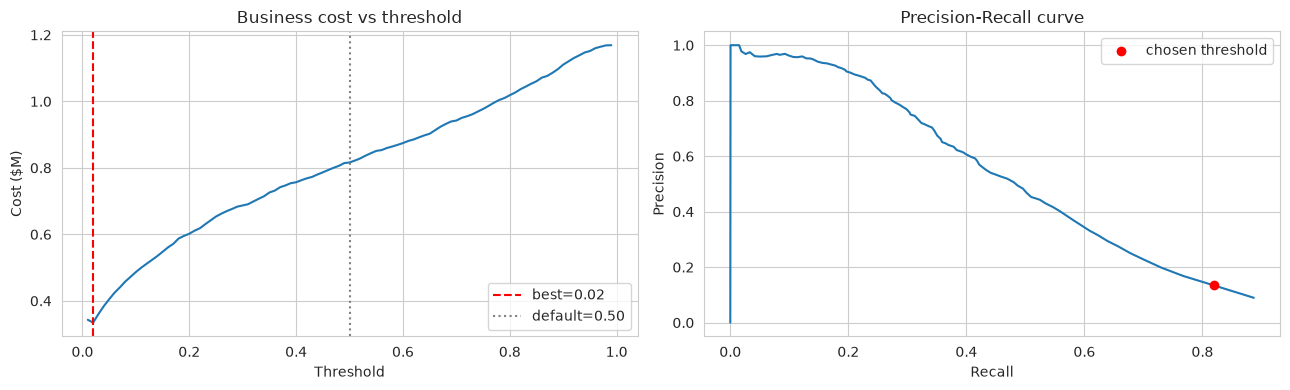

In [12]:
FN_COST, FP_COST = 500, 10   # dollars — justify these in the README
thresholds = np.linspace(0.01, 0.99, 99)

def cost_curve(y_true, y_proba):
    rows = []
    for t in thresholds:
        pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        rows.append({
            "threshold":  t,
            "precision":  tp/(tp+fp) if tp+fp else 0,
            "recall":     tp/(tp+fn) if tp+fn else 0,
            "fp":         fp, "fn": fn, "tp": tp,
            "cost":       fn*FN_COST + fp*FP_COST,
        })
    return pd.DataFrame(rows)

# Use the better model (LightGBM)
df_curve = cost_curve(y_val, proba_lgb)
best = df_curve.loc[df_curve["cost"].idxmin()]

print(f"Optimal threshold: {best['threshold']:.2f}")
print(f"  recall    = {best['recall']:.3f}")
print(f"  precision = {best['precision']:.3f}")
print(f"  TP={int(best['tp']):,}  FP={int(best['fp']):,}  FN={int(best['fn']):,}")
print(f"  Cost      = ${best['cost']:,.0f}")

# Compare to threshold 0.5
default = df_curve.iloc[(df_curve["threshold"] - 0.5).abs().argmin()]
savings = default["cost"] - best["cost"]
print(f"\nCost at threshold 0.5: ${default['cost']:,.0f}")
print(f"Savings from tuning : ${savings:,.0f}  ({savings/default['cost']*100:.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df_curve["threshold"], df_curve["cost"] / 1e6)
ax[0].axvline(best["threshold"], color="red", ls="--", label=f"best={best['threshold']:.2f}")
ax[0].axvline(0.5, color="gray", ls=":", label="default=0.50")
ax[0].set(title="Business cost vs threshold", xlabel="Threshold", ylabel="Cost ($M)")
ax[0].legend()

ax[1].plot(df_curve["recall"], df_curve["precision"])
ax[1].scatter([best["recall"]], [best["precision"]], color="red", zorder=5, label="chosen threshold")
ax[1].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
ax[1].legend()
plt.tight_layout(); plt.savefig(REPORTS_DIR / "cost_threshold.png", dpi=120); plt.show()

In [13]:
best_threshold = float(best["threshold"])
m_final = evaluate(f"LightGBM @ t={best_threshold:.2f}", y_val, proba_lgb,
                   threshold=best_threshold)


────────────────────────────────────────────────────
LightGBM @ t=0.02  (threshold=0.02)
────────────────────────────────────────────────────
  roc_auc         0.9436
  pr_auc          0.5015
  recall@fpr1%    0.5064
  precision       0.1339
  recall          0.8199
  f1              0.2302
  TP=1,917  FP=12,397  FN=421  TN=125,257


## 4. Why does the model predict fraud?
SHAP tells us which features push each prediction up or down.

/home/prashant/Projects/fraud-detection-2026/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


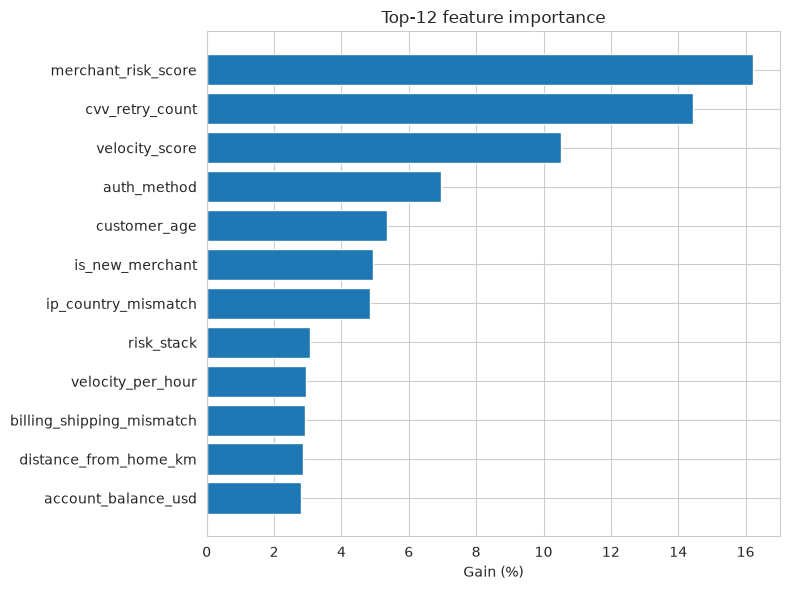

                  feature          gain  gain_pct
      merchant_risk_score 144701.017497 16.210702
          cvv_retry_count 128914.935489 14.442204
           velocity_score  93772.502950 10.505235
              auth_method  62005.871844  6.946452
             customer_age  47732.744376  5.347449
          is_new_merchant  44165.020824  4.947761
      ip_country_mismatch  43268.899343  4.847369
               risk_stack  27501.152967  3.080925
        velocity_per_hour  26364.590934  2.953597
billing_shipping_mismatch  26033.215818  2.916474
    distance_from_home_km  25640.526442  2.872481
      account_balance_usd  25087.742568  2.810553


/home/prashant/Projects/fraud-detection-2026/venv/lib/python3.14/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


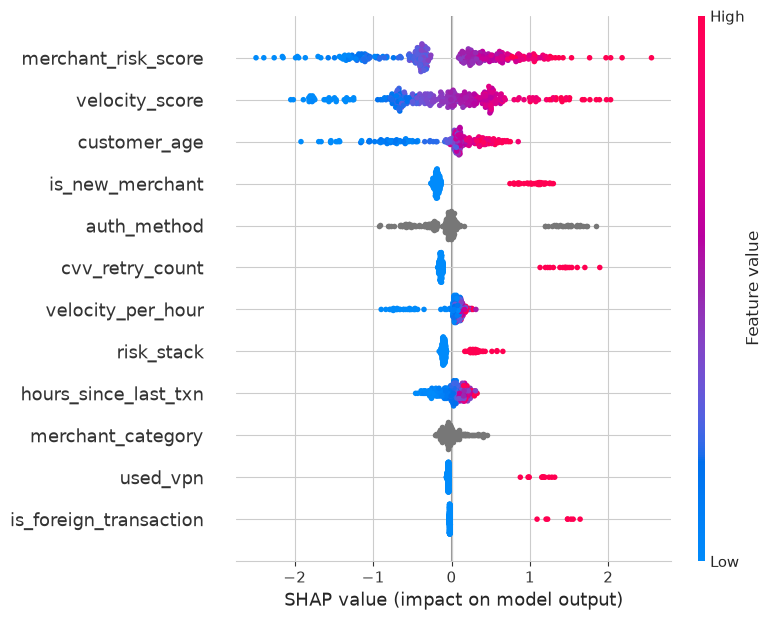

In [14]:
import shap

# --- Global importance ---
fi = pd.DataFrame({
    "feature": lgb_model.booster_.feature_name(),
    "gain":    lgb_model.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
fi["gain_pct"] = fi["gain"] / fi["gain"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
top = fi.head(12).iloc[::-1]
ax.barh(top["feature"], top["gain_pct"])
ax.set(xlabel="Gain (%)", title="Top-12 feature importance")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "feature_importance.png", dpi=120); plt.show()
print(fi.head(12).to_string(index=False))

# --- SHAP on a sample (300 rows for speed) ---
idx = np.random.RandomState(42).choice(len(Xva_lgb), size=min(300, len(Xva_lgb)), replace=False)
sample = Xva_lgb.iloc[idx]
explainer = shap.TreeExplainer(lgb_model)
sv = explainer.shap_values(sample)

shap.summary_plot(sv, sample, show=False, max_display=12)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
# ---- Final test predictions ----
# Refit the LGBM model on ALL training data (train + val) for production
# (In a real deployment you'd retrain; here we refit with early stopping on val as proxy)
X_full_lgb, _ = prep_for_lgb(X, X_val)   # categorical cast for full X
final_model = lgb.LGBMClassifier(
    n_estimators=lgb_model.best_iteration_,
    learning_rate=0.03, num_leaves=127, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=0.1,
    objective="binary", n_jobs=-1, random_state=42, verbose=-1,
)
final_model.fit(X_full_lgb, y)

# Prep test with the same categorical dtypes
X_test_lgb = X_test_final.copy()
for c in cat_cols:
    X_test_lgb[c] = X_test_lgb[c].fillna("__NA__").astype("category")

proba_test = final_model.predict_proba(X_test_lgb)[:, 1]
pred_test  = (proba_test >= best_threshold).astype(int)

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: pred_test})
submission.to_csv(PROJECT_ROOT / "submission.csv", index=False)
print(f"Submission written: {PROJECT_ROOT / 'submission.csv'}")
print(submission[TARGET].value_counts().to_string())
print(f"Predicted fraud rate: {submission[TARGET].mean()*100:.3f}%  (train: 1.67%)")

Submission written: /home/prashant/Projects/fraud-detection-2026/submission.csv
is_fraud
0    268833
1     31151
Predicted fraud rate: 10.384%  (train: 1.67%)
